# Andy Trader: Fast Book vs Real Ask Prices

## Name: Dawn Andrei Pamesa


In [1]:
import sqlite3
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Loading the Predictions

In [2]:
con = sqlite3.connect("file:D:/Andy Trader/crypto_observations.db?mode=ro", uri=True)

preds = pd.read_sql_query("select instrument, probability_up, created_at, outcome_up, features_json from crypto_predictions where predictor = 'fast:continuation' and settled_at is not null and outcome_up is not null and instrument = 'BTC-USD'", con)
preds.head()

,instrument,probability_up,created_at,outcome_up,features_json
0,BTC-USD,0.933333,2026-09-06T17:18:10.157090+00:00,1,"{""curve_counts"": [93, 55, 30, 8, 4, 1, 0], ""de..."
1,BTC-USD,0.935484,2026-09-06T18:08:09.792489+00:00,1,"{""curve_counts"": [97, 60, 31, 8, 4, 1, 0], ""de..."
2,BTC-USD,0.062500,2026-09-06T18:48:09.824730+00:00,0,"{""curve_counts"": [99, 65, 32, 8, 4, 1, 0], ""de..."
3,BTC-USD,0.060606,2026-09-06T19:03:01.853177+00:00,0,"{""curve_counts"": [101, 65, 33, 8, 4, 1, 0], ""d..."
4,BTC-USD,0.941176,2026-09-06T21:03:01.920661+00:00,1,"{""curve_counts"": [116, 72, 34, 9, 4, 1, 0], ""d..."


In [3]:
print("Shape:", preds.shape)

Shape: (2713, 5)


In [4]:
preds["outcome_up"].value_counts()

outcome_up
0    1508
1    1205
Name: count, dtype: int64

Finding the Round

In [5]:
preds["round_start"] = preds["features_json"].apply(lambda s: json.loads(s)["round_start"])
preds["created_at"] = pd.to_datetime(preds["created_at"], utc=True, format="ISO8601")
preds["round_start"] = pd.to_datetime(preds["round_start"], utc=True, format="ISO8601")

In [6]:
# The order book rounds are named by the start of the round in epoch seconds.
preds["round_id"] = "btc-updown-5m-" + preds["round_start"].dt.as_unit("s").astype("int64").astype(str)
preds[["created_at", "round_start", "round_id"]].head()

,created_at,round_start,round_id
0,2026-09-06 17:18:10.157090+00:00,2026-09-06 17:15:00+00:00,btc-updown-5m-1788714900
1,2026-09-06 18:08:09.792489+00:00,2026-09-06 18:05:00+00:00,btc-updown-5m-1788717900
2,2026-09-06 18:48:09.824730+00:00,2026-09-06 18:45:00+00:00,btc-updown-5m-1788720300
3,2026-09-06 19:03:01.853177+00:00,2026-09-06 19:00:00+00:00,btc-updown-5m-1788721200
4,2026-09-06 21:03:01.920661+00:00,2026-09-06 21:00:00+00:00,btc-updown-5m-1788728400


Loading the Order Book

In [7]:
obs = pd.read_sql_query("select round_id, observed_at, up_best_ask, down_best_ask, up_best_ask_depth_shares, down_best_ask_depth_shares from complete_set_observations where round_id like 'btc-updown-5m-%'", con)
obs["observed_at"] = pd.to_datetime(obs["observed_at"], utc=True, format="ISO8601")
print("Shape:", obs.shape)

Shape: (172003, 6)


Matching Each Prediction to the Order Book

In [8]:
# Take the first snapshot at or after the prediction, but no more than 20 seconds later.
preds = preds.sort_values("created_at")
obs = obs.sort_values("observed_at")

matched = pd.merge_asof(preds, obs, left_on="created_at", right_on="observed_at", by="round_id",
                        direction="forward", tolerance=pd.Timedelta("20s"))
matched = matched.dropna(subset=["observed_at"])

print("Predictions:", len(preds))
print("Matched to an order book:", len(matched))

Predictions: 2713
Matched to an order book: 1591


C:\Users\Dawn\AppData\Local\Temp\ipykernel_33788\1372089712.py:6: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  direction="forward", tolerance=pd.Timedelta("20s"))


Price Paid and Result

In [9]:
matched["bet_up"] = matched["probability_up"] > 0.5
matched["ask"] = np.where(matched["bet_up"], matched["up_best_ask"], matched["down_best_ask"])
matched["depth"] = np.where(matched["bet_up"], matched["up_best_ask_depth_shares"], matched["down_best_ask_depth_shares"])
matched["win"] = (matched["outcome_up"] == 1) == matched["bet_up"]
matched = matched[matched["ask"] > 0].copy()

# A contract pays 1.00 if the bet wins, so the profit is the payout minus the ask.
matched["pnl"] = matched["win"].astype(float) - matched["ask"]
matched[["created_at", "bet_up", "ask", "depth", "win", "pnl"]].head()

,created_at,bet_up,ask,depth,win,pnl
0,2026-09-06 17:18:10.157090+00:00,True,0.99,2775.82,True,0.01
2,2026-09-06 18:48:09.824730+00:00,False,0.92,16.08,True,0.08
17,2026-09-07 00:58:02.050488+00:00,False,0.84,61.34,False,-0.84
19,2026-09-07 01:18:10.139563+00:00,True,0.93,36.91,False,-0.93
22,2026-09-07 03:38:10.086022+00:00,False,0.96,188.00,True,0.04


In [10]:
print("Rows:", len(matched))
print("Hit rate:", round(matched["win"].mean(), 3))
print("Average ask paid:", round(matched["ask"].mean(), 3))
print("Average profit per contract:", round(matched["pnl"].mean(), 4))

Rows: 1128
Hit rate: 0.851
Average ask paid: 0.878
Average profit per contract: -0.0269


Profit by Ask Price

In [11]:
matched["ask_bucket"] = pd.cut(matched["ask"], bins=[0, 0.3, 0.5, 0.7, 0.8, 0.9, 1.0])
by_bucket = matched.groupby("ask_bucket", observed=True)["pnl"].agg(["count", "mean"])
by_bucket

,count,mean
ask_bucket,,
"(0.0, 0.3]",31,0.381290
"(0.3, 0.5]",33,0.147273
"(0.5, 0.7]",76,0.025658
"(0.7, 0.8]",82,0.010854
"(0.8, 0.9]",155,-0.064871
"(0.9, 1.0]",751,-0.052999


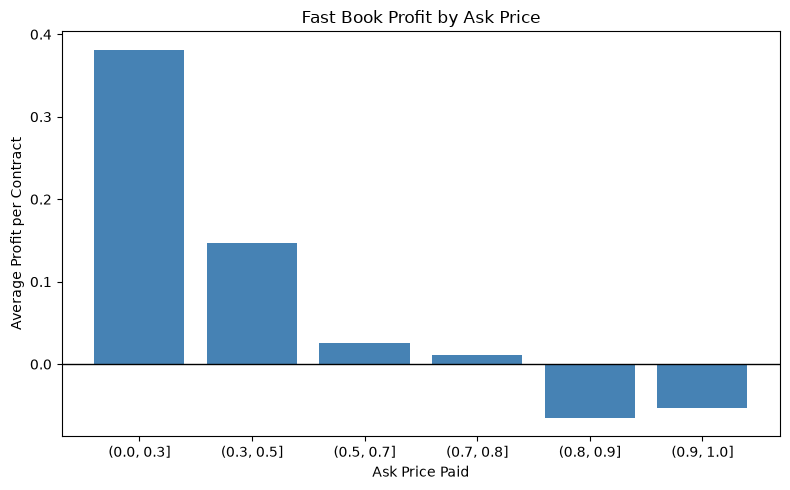

In [12]:
plt.figure(figsize=(8, 5))
plt.bar(by_bucket.index.astype(str), by_bucket["mean"], color="steelblue")
plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Ask Price Paid")
plt.ylabel("Average Profit per Contract")
plt.title("Fast Book Profit by Ask Price")
plt.tight_layout()
plt.show()

The Cheap Asks

In [13]:
cheap = matched[matched["ask"] < 0.70].sort_values("created_at")
print("Rows with an ask under 0.70:", len(cheap))
print("Hit rate:", round(cheap["win"].mean(), 3))
print("Average profit per contract:", round(cheap["pnl"].mean(), 4))

Rows with an ask under 0.70: 137
Hit rate: 0.591
Average profit per contract: 0.1294


Is It Just Noise

In [14]:
# Resample the cheap rows 2000 times to see how far the average could move by chance.
rng = np.random.default_rng(42)
boot_means = rng.choice(cheap["pnl"].to_numpy(), size=(2000, len(cheap))).mean(axis=1)
print("95% interval for the average profit:", np.percentile(boot_means, [2.5, 97.5]).round(4))

95% interval for the average profit: [0.0392 0.2125]


Does the Order Book Have Depth

In [15]:
print("Median shares at the ask (cheap rows):", cheap["depth"].median())
deep = cheap[cheap["depth"] >= 10]
print("Cheap rows with at least 10 shares:", len(deep))
print("Average profit per contract:", round(deep["pnl"].mean(), 4))

Median shares at the ask (cheap rows): 264.36
Cheap rows with at least 10 shares: 131
Average profit per contract: 0.1315


First Half vs Second Half

In [16]:
half = len(cheap) // 2
print("First half average profit:", round(cheap["pnl"].iloc[:half].mean(), 4))
print("Second half average profit:", round(cheap["pnl"].iloc[half:].mean(), 4))

First half average profit: 0.1115
Second half average profit: 0.1471


Fees

In [17]:
print("Average profit after a 0.01 fee:", round(cheap["pnl"].mean() - 0.01, 4))
print("Average profit after a 0.02 fee:", round(cheap["pnl"].mean() - 0.02, 4))

Average profit after a 0.01 fee: 0.1194
Average profit after a 0.02 fee: 0.1094


Summary

In [18]:
low, high = np.percentile(boot_means, [2.5, 97.5])

print("Overall the fast book won", round(matched["win"].mean() * 100, 1), "percent of its", len(matched), "bets.")
print("It paid an average ask of", round(matched["ask"].mean(), 3), "so the order book had already priced in most of the move.")
print("The average profit per contract was", round(matched["pnl"].mean(), 4), "which is below zero.")
print()
print("When the ask was under 0.70 there were", len(cheap), "bets and the average profit was", round(cheap["pnl"].mean(), 4), "per contract.")
print("The 95 percent interval for that average runs from", round(low, 4), "to", round(high, 4), "so it stays above zero.")
print("The first half earned", round(cheap["pnl"].iloc[:half].mean(), 4), "and the second half earned", round(cheap["pnl"].iloc[half:].mean(), 4), "so it was not a one-time spike.")
print("The order book was deep, with a median of", cheap["depth"].median(), "shares at the ask.")
print("A 0.02 fee would still leave", round(cheap["pnl"].mean() - 0.02, 4), "per contract.")
print()
print("This is a lead and not proof. The 0.70 cut was chosen after looking at this same data, so it needs a forward test on new rounds.")


Overall the fast book won 85.1 percent of its 1128 bets.
It paid an average ask of 0.878 so the order book had already priced in most of the move.
The average profit per contract was -0.0269 which is below zero.

When the ask was under 0.70 there were 137 bets and the average profit was 0.1294 per contract.
The 95 percent interval for that average runs from 0.0392 to 0.2125 so it stays above zero.
The first half earned 0.1115 and the second half earned 0.1471 so it was not a one-time spike.
The order book was deep, with a median of 264.36 shares at the ask.
A 0.02 fee would still leave 0.1094 per contract.

This is a lead and not proof. The 0.70 cut was chosen after looking at this same data, so it needs a forward test on new rounds.
